# Communicate with a vLLM-served Qwen3-VL-32B model

Sanity-check notebook: pick a sample, overlay bbox annotations on the video, save to disk, then send to the local vLLM server and print the model's answer.

**Prerequisites:** launch the server with `bash bash_scripts/vllm_serving/qwen3vl32b.sh`.

---
# Section 1: V-STaR Dataset

## 1. Load the V-STaR test set

In [1]:
import json
import datasets

dataset = datasets.load_dataset("json", data_files="/projects/torresani-lab/ajay/datasets/V-STaR/V_STaR_test_with_qid.json", split="train")
print(len(dataset))

2094


## 2. Pick a sample and decode its video

In [3]:
import os
import sys
import importlib

import numpy as np
import pandas as pd
import torch
from qwen_vl_utils import fetch_video

sys.path.append("/projects/torresani-lab/ajay/visual-grounded-vlm/")
import src.utils.annotation_utils
importlib.reload(src.utils.annotation_utils)
from src.utils.annotation_utils import load_mask_annotations, annotate_frames

# Build the pool of qids the model got wrong (verdict == False) from an eval run's CSV
EVAL_CSV = "/scratch/rajendrakumar.a/visual-grounded-vlm/results/qwen25vl7bi_vstar_zeroshot/2026-05-18_18-35-15/benchmark/evaluation_results.csv"
eval_df = pd.read_csv(EVAL_CSV)
wrong_qids = set(eval_df.loc[~eval_df["verdict"].astype(str).str.lower().eq("true"), "qid"])
wrong_idxs = [i for i, s in enumerate(dataset) if s["qid"] in wrong_qids]
print(f"{len(wrong_idxs)} wrong samples in pool")

# Pick the idx-th wrong sample and decode at fixed token budget
idx = 2
# sample = dataset[wrong_idxs[idx]]
sample = dataset[idx]
print(sample['vid'], sample['qid'])

video_path = os.path.join("/projects/torresani-lab/ajay/datasets/V-STaR/videos", sample['vid'] + ".mp4")
video_input = fetch_video({
    "video": video_path,
    "max_pixels": 512 * 28 * 28,
    "fps": 1,
})
print("video_input:", video_input.shape)

915 wrong samples in pool
6297019062 6297019062_0
video_input: torch.Size([58, 3, 364, 644])


## 3. Overlay annotations on the decoded frames

In [4]:
annotation_root = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/vstar/uniform_sample_cap_768/2026-05-19_19-14-38"
annotation_type = "bbox"  # "bbox" | "mask" | "outline"

# Options
annotate_bbox = True
annotate_frame_nums = False

annotated_input = video_input.clone()

if annotate_bbox:
    annotation_path = os.path.join(annotation_root, "masks", f"{sample['qid']}.json")
    record = load_mask_annotations(annotation_path)
    annotated_input = annotate_frames(annotated_input, record["masks_np"], annotation_type=annotation_type, thickness=2)
    annotated_input = torch.tensor(np.array(annotated_input)).permute(0, 3, 1, 2).to(torch.float32)

# Uniformly sample 16 frames
indices = np.linspace(0, annotated_input.shape[0] - 1, 16, dtype=int)
annotated_input = annotated_input[indices]

if annotate_frame_nums:
    import cv2

    def annotate_frame_numbers(frames: torch.Tensor, scale: float = 2.0, thickness: int = 3) -> torch.Tensor:
        annotated = []
        for i, frame in enumerate(frames):
            arr = cv2.cvtColor(frame.permute(1, 2, 0).numpy().astype(np.uint8), cv2.COLOR_RGB2BGR)
            h, w = arr.shape[:2]
            text = str(i)
            font = cv2.FONT_HERSHEY_SIMPLEX
            (tw, th), baseline = cv2.getTextSize(text, font, scale, thickness)
            x, y = w - tw - 8, h - baseline - 4
            cv2.putText(arr, text, (x, y), font, scale, (0, 0, 255), thickness, cv2.LINE_AA)
            annotated.append(torch.from_numpy(cv2.cvtColor(arr, cv2.COLOR_BGR2RGB)).permute(2, 0, 1))
        return torch.stack(annotated)

    annotated_input = annotate_frame_numbers(annotated_input)

print("annotated_input:", annotated_input.shape)

annotated_input: torch.Size([16, 3, 364, 644])


## 4. Write the annotated video to disk

In [5]:
from torchcodec.encoders import VideoEncoder

dump_dir = "/projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serving/dump"
os.makedirs(dump_dir, exist_ok=True)
output_video_path = os.path.join(dump_dir, f"ann_{sample['qid']}.mp4")
VideoEncoder(annotated_input.to(torch.uint8), frame_rate=4).to_file(output_video_path)
print("wrote:", output_video_path)

wrote: /projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serving/dump/ann_6297019062_0.mp4


## 5. Preview a random annotated frame

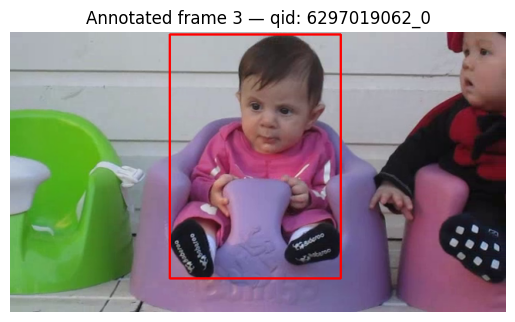

In [6]:
import matplotlib.pyplot as plt

random_idx = np.random.randint(0, annotated_input.shape[0])
any_frame = annotated_input[random_idx].permute(1, 2, 0).numpy().astype(np.uint8)
plt.imshow(any_frame)
plt.title(f"Annotated frame {random_idx} — qid: {sample['qid']}")
plt.axis('off')
plt.show()

## 6. Build the chat request and send to vLLM

In [7]:
from openai import OpenAI

openai_api_key = "EMPTY"
openai_api_base = "http://localhost:8000/v1"
model = "Qwen/Qwen3-VL-32B-Instruct"

# SYSTEM_PROMPT_PATH = "/projects/torresani-lab/ajay/visual-grounded-vlm/prompts/train/openo3_red_bbox_frame_num_v2.md"
SYSTEM_PROMPT_PATH = "/projects/torresani-lab/ajay/visual-grounded-vlm/prompts/rcap/v3_3.md"
with open(SYSTEM_PROMPT_PATH, "r") as f:
    SYSTEM_PROMPT = f.read()

n_frames = annotated_input.shape[0]
# frame_prompt = "".join(f"Frame {i}: <image>\n" for i in range(n_frames))

message = [
    {
        "role": "system",
        "content": [{"type": "text", "text": SYSTEM_PROMPT}],
    },
    {
        "role": "user",
        "content": [
            # {"type": "text", "text": frame_prompt + sample['question']},
            {"type": "text", "text": sample['question']},
            # {"type": "text", "text": "Is the man who watches the other adult man in black wearing a bunny hat?"},
            {
                "type": "video_url",
                "video_url": {"url": "file://" + output_video_path},
                "VIDEO_MAX_PIXELS": 1024 * 28 * 28,
                "fps": 1,
            },
        ],
    },
]

client = OpenAI(api_key=openai_api_key, base_url=openai_api_base)

In [8]:
import re

# pull the stored prediction for this qid from the eval CSV (CoT, if any, is inline as <think>...</think>)
pred = eval_df.loc[eval_df["qid"] == sample["qid"], "generated_answer"].iloc[0]
cot = re.search(r"<think>(.*?)</think>", str(pred), re.DOTALL)

print(f"QID = {sample['qid']}")
print(f"Question: {sample['question']}")
if cot:
    print(f"Predicted CoT: {cot.group(1).strip()}")
print(f"Generated answer: {pred}")
print(f"Ground truth answer: {sample['answer']}")

QID = 6297019062_0
Question: who is above the round and pink baby seat?
Generated answer: A baby is above the round and pink baby seat.
Ground truth answer: there is a baby above the round and pink baby seat.


## RCAP

In [9]:
chat_response = client.chat.completions.create(
    model=model,
    messages=message,
    max_tokens=768,
    seed=42,
    temperature=0,
)
response_text = chat_response.choices[0].message.content
print(response_text)

<caption>The red bounding box highlights a baby seated in a colorful, round, and pink baby seat. The baby is wearing a pink outfit with white polka dots and black shoes with white text. The baby is sitting upright, looking around, and occasionally moving their hands. The seat is part of a row of similar baby seats, each with a different color and design, and the baby is positioned in the center of the frame. The background consists of a white wooden wall. The baby appears calm and engaged with their surroundings.</caption>


## Variant-1: RCAP + question (no video) -> Qwen3-VL-32B -> Answer + Reason

In [20]:
# question = sample['question']
question = "who is sitting above the pink baby seat?"
print(f"Question: {question}")
qa_prompt = (
    "You are given a region caption describing the entity highlighted in a video, "
    "and a question about the video.\n\n"
    f"Region caption: {response_text}\n\n"
    f"Question: {question}\n\n"
    "Think carefully before answering. Then return a JSON object with two fields:\n"
    '- "answer": your answer to the question\n'
    '- "reason": the reasoning behind your answer\n'
)

qa_message = [
    {
        "role": "user",
        "content": [{"type": "text", "text": qa_prompt}],
    },
]

qa_response = client.chat.completions.create(
    model=model,
    messages=qa_message,
    max_tokens=768,
    seed=42,
    temperature=0,
    response_format={"type": "json_object"},
)
print(qa_response.choices[0].message.content)

Question: who is sitting above the pink baby seat?
{
  "answer": "No one is sitting above the pink baby seat.",
  "reason": "The region caption describes a baby seated in a pink baby seat, which is part of a row of similar seats. The baby is sitting upright and looking around, but there is no mention of anyone or anything positioned above the seat. The background is described as a white wooden wall, and no other individuals or objects are noted in the area above the seat. Therefore, based on the provided information, no one is sitting above the pink baby seat."
}


## Zeroshot

In [11]:
# zeroshot verification: send the question + unannotated video directly to the model
# write the raw (unannotated) decoded video to disk, subsampling the same 16 frames
zs_indices = np.linspace(0, video_input.shape[0] - 1, 16, dtype=int)
zs_video_path = os.path.join(dump_dir, f"zeroshot_{sample['qid']}.mp4")
VideoEncoder(video_input[zs_indices].to(torch.uint8), frame_rate=4).to_file(zs_video_path)

# same JSON output format as the rcap-grounded QA: think, then answer + reason
zs_prompt = (
    f"Question: {sample['question']}\n\n"
    "Think carefully before answering. Then return a JSON object with two fields:\n"
    '- "answer": your answer to the question\n'
    '- "reason": the reasoning behind your answer\n'
)

zs_message = [
    {
        "role": "user",
        "content": [
            {"type": "text", "text": zs_prompt},
            {
                "type": "video_url",
                "video_url": {"url": "file://" + zs_video_path},
                "VIDEO_MAX_PIXELS": 128 * 28 * 28,
                "fps": 1,
            },
        ],
    },
]

zs_response = client.chat.completions.create(
    model=model,
    messages=zs_message,
    max_tokens=768,
    seed=42,
    temperature=0,
    response_format={"type": "json_object"},
)
print(zs_response.choices[0].message.content)

{
  "answer": "A baby wearing a yellow hat and a yellow outfit",
  "reason": "In the first frame, the baby in the round and pink baby seat is wearing a pink outfit and black shoes. Above this baby, in the frame, is another baby seated in a green chair, wearing a yellow hat and a yellow outfit with orange and green striped leggings. This baby is positioned directly above the baby in the pink seat in the visual composition of the frame. The subsequent frames show different babies in the pink seat, but the question refers to the initial frame where the baby in the yellow outfit is clearly above the one in the pink seat."
}


## Variant 2: RCAP + question + annotated video → Qwen3-VL-32B → Answer + Reason

In [103]:
# Variant 2: region caption + question + annotated video -> reason then answer in JSON
v2_prompt = (
    "You are given a region caption describing the entity highlighted (red bounding box) in the video, "
    "and a question about the video.\n\n"
    f"Region caption: {response_text}\n\n"
    f"Question: {sample['question']}\n\n"
    "Think carefully before answering. Then return a JSON object with two fields:\n"
    '- "answer": your answer to the question\n'
    '- "reason": the reasoning behind your answer\n'
)

v2_message = [
    {
        "role": "user",
        "content": [
            {"type": "text", "text": v2_prompt},
            {
                "type": "video_url",
                "video_url": {"url": "file://" + output_video_path},
                "VIDEO_MAX_PIXELS": 1024 * 28 * 28,
                "fps": 1,
            },
        ],
    },
]

v2_response = client.chat.completions.create(
    model=model,
    messages=v2_message,
    max_tokens=768,
    seed=42,
    temperature=0,
    response_format={"type": "json_object"},
)
print(v2_response.choices[0].message.content)

{
  "answer": "A black car parked behind a white metal fence",
  "reason": "The region caption explicitly describes the red bounding box highlighting a black car parked behind a white metal fence in the background. The video frames show this car positioned to the left side of the frame, behind the children who are raking grain. The adult in black is visible in the background, standing near the fence, and the black car is located behind this adult. Therefore, based on the visual evidence and the provided caption, the object behind the adult in black is the black car."
}


## Question-conditioned video summary (no answer)

In [112]:
# question-conditioned video summary + relevant items, returned as JSON (do NOT answer the question)
summary_prompt = (
    f"Question: {sample['question']}\n\n"
    "Describe the video, emphasizing the parts most relevant to the question above. "
    "Describe only what is visually present; do not answer the question. Focus on the "
    "main elements, not fine details.\n\n"
    "First generate the summary, then from it pick the items needed to answer the question. "
    "Return a JSON object with two fields:\n"
    '- "summary": a concise summary of the video\n'
    '- "items": a list of only the distinct, visually-grounded entities that are relevant '
    "to answering the question. Each item must be a noun (with optional modifiers) that "
    "refers to a single object that can be individually isolated/localized in the frame "
    "(e.g. \"black car\", \"white metal fence\"), not abstract or uncountable concepts "
    "(e.g. \"background\", \"visibility\", \"daytime\").\n"
)

summary_message = [
    {
        "role": "user",
        "content": [
            {"type": "text", "text": summary_prompt},
            {
                "type": "video_url",
                "video_url": {"url": "file://" + output_video_path},
                "VIDEO_MAX_PIXELS": 1024 * 28 * 28,
                "fps": 1,
            },
        ],
    },
]

summary_response = client.chat.completions.create(
    model=model,
    messages=summary_message,
    max_tokens=768,
    seed=42,
    temperature=0,
    response_format={"type": "json_object"},
)
print(summary_response.choices[0].message.content)

{
  "summary": "Two young girls are raking a large pile of grain spread out on a paved surface. They are using a wooden rake with a long handle. In the background, there is a white metal fence, a sidewalk, and a few adults standing or walking. A dark-colored car is visible behind the fence, moving from left to right. The setting appears to be outdoors during the daytime, with clear visibility and shadows indicating sunlight.",
  "items": [
    "dark-colored car",
    "white metal fence",
    "sidewalk",
    "adults"
  ]
}


---
# Section 2: Open-o3-Video Dataset (STGR)

## OO3-1. Load dataset and track manifest

In [1]:
import sys
sys.path.append("/projects/torresani-lab/ajay/visual-grounded-vlm/")

import importlib
import json
import os

import cv2
import numpy as np
import torch
from datasets import load_dataset
from qwen_vl_utils import fetch_video

import src.utils.openo3_utils as openo3_utils
importlib.reload(openo3_utils)
from src.utils.openo3_utils import (
    get_video_path, splice_keyframes,
    load_track_manifest, load_track_masks, masks_to_bboxes,
)

# --- config ---
OO3_JSON    = "/projects/torresani-lab/ajay/datasets/Open-o3-Video/json_data/STGR-SFT.json"
RESULTS_DIR = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/openo3video/uniform_sample_1fps_orig_res_track"

dataset_oo3 = load_dataset("json", data_files=OO3_JSON, split="train")
str_dataset = [s for s in dataset_oo3 if s["task"] == "temporal-spatial free-form QA"]
run_meta, samples = load_track_manifest(RESULTS_DIR)

print(f"Loaded {len(str_dataset)} STGR samples")
print(f"Track manifest: {len(samples)} entries")

Loaded 7047 STGR samples
Track manifest: 7047 entries


## OO3-2. Pick a sample and reconstruct the annotated video

In [9]:
# --- config ---
SAMPLE_IDX    = 0
VIDEO_FPS     = run_meta["config"]["video"]["fps"]
TGT_FRAMES    = 32
ANNOTATE_BBOX = True

sample_oo3 = str_dataset[SAMPLE_IDX]
sample_entry = samples[sample_oo3["id"]]

print(f"Sample {SAMPLE_IDX}  id={sample_oo3['id']}")
print(f"Q: {sample_oo3['question']}")
print(f"A: {sample_oo3['answer']}")
print(f"Concepts: {[c['concept'] for c in sample_entry['concepts']]}")

Sample 0  id=000000
Q: Who is the man seen enjoying a beer with others at the table?
A: The man is Barack Obama. He is shown holding a glass of beer, smiling, and interacting with other people seated at an outdoor table.
Concepts: ['man', 'beer glass']


## OO3-3. Build annotated frame stack (1fps + spliced keyframes + bbox overlays)

In [10]:
# reconstruct augmented frame stack (same as sam3_track.py)
frames = fetch_video({"video": get_video_path(sample_oo3), "fps": VIDEO_FPS})
frames_list = list(frames.permute(0, 2, 3, 1).cpu().numpy().astype("uint8"))
H, W = frames_list[0].shape[:2]
splice_keyframes(sample_oo3, frames_list, H, W)
frames_aug = np.stack(frames_list)  # (T, H, W, 3)
T = len(frames_aug)
print(f"Augmented frame stack: {T} frames, {W}x{H}")

annotated = frames_aug.copy()

if ANNOTATE_BBOX:
    masks_dict = load_track_masks(sample_entry, RESULTS_DIR)
    concepts = list(masks_dict.keys())
    print(f"{len(concepts)} track(s) available: {concepts}")

    # overlay every concept's bbox track onto the frame stack (all red)
    for concept in concepts:
        bboxes = masks_to_bboxes(masks_dict[concept], target_size=(H, W))
        for t, (x1, y1, x2, y2) in enumerate(bboxes.astype(int)):
            if x2 > x1 and y2 > y1:
                cv2.rectangle(annotated[t], (x1, y1), (x2, y2), color=(255, 0, 0), thickness=2)

# subsample to TGT_FRAMES
indices = np.linspace(0, T - 1, TGT_FRAMES, dtype=int)
annotated_input_oo3 = torch.tensor(annotated[indices]).permute(0, 3, 1, 2).to(torch.float32)
print(f"annotated_input: {annotated_input_oo3.shape}")

Augmented frame stack: 66 frames, 448x252
2 track(s) available: ['man', 'beer glass']
annotated_input: torch.Size([32, 3, 252, 448])


## OO3-4. Preview a random annotated frame

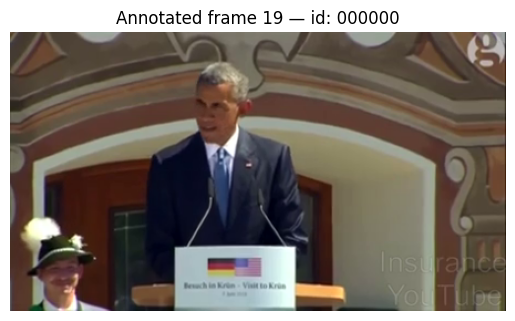

In [11]:
import matplotlib.pyplot as plt

random_idx = np.random.randint(0, annotated_input_oo3.shape[0])
any_frame = annotated_input_oo3[random_idx].permute(1, 2, 0).numpy().astype(np.uint8)
plt.imshow(any_frame)
plt.title(f"Annotated frame {random_idx} — id: {sample_oo3['id']}")
plt.axis('off')
plt.show()

## OO3-5. Save annotated video to disk

In [12]:
from torchcodec.encoders import VideoEncoder

dump_dir = "/projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serving/dump"
os.makedirs(dump_dir, exist_ok=True)
output_video_path_oo3 = os.path.join(dump_dir, f"oo3_ann_{sample_oo3['id']}.mp4")
VideoEncoder(annotated_input_oo3.to(torch.uint8), frame_rate=4).to_file(output_video_path_oo3)
print("wrote:", output_video_path_oo3)

wrote: /projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serving/dump/oo3_ann_000000.mp4


## OO3-6. Build the chat request and send to vLLM

In [13]:
# def create_user_prompt(video_summary, question, concept_captions, answer=None):
#     prompt = f"Video summary: {video_summary}\n"
#     prompt += f"Question: {question}\n"
#     prompt += "Relevant concepts and their captions:\n"
#     for concept, caption in concept_captions.items():
#         prompt += f"- {concept}: {caption}\n"
#     if answer is not None:
#         prompt += f"Answer: {answer}\n"
#     return prompt
def create_user_prompt(video_summary, question, concept_captions, answer=None):
    prompt = f"{video_summary}\n"
    prompt += "Red bounding box annotated objects/entities in the video:\n"
    for concept, caption in concept_captions.items():
        prompt += f"- {concept}: {caption}\n"
    prompt += f"Question: {question}\n"
    if answer is not None:
        prompt += f"Ground Truth Answer: {answer}\n"
    return prompt

# load the PLM rcap outputs (video summary + per-concept captions) for the current sample
RCAP_DIR = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/openo3video/openo3_str_plm_rcap"
rcap = json.load(open(os.path.join(RCAP_DIR, "samples", f"{sample_oo3['id']}.json")))

user_prompt = create_user_prompt(
    video_summary=rcap["video_summary"],
    question=sample_oo3["question"],
    concept_captions=rcap["concept_captions"],
    answer=sample_oo3["answer"],
)
print(user_prompt)

The video features former President Barack Obama and German Chancellor Angela Merkel addressing a crowd of people in traditional German dress. The video cuts to President Obama addressing the crowd from a podium, then to him sitting at a table with others, drinking beer and eating food.
The video begins with President Obama and Chancellor Merkel walking through a crowd of people in traditional German dress. The video cuts to President Obama standing at a podium, addressing the crowd. The video cuts to a shot of the crowd clapping. The video cuts back to President Obama at the podium, then to him sitting at a table with others, drinking beer and eating food.
The video features a crowd of people in traditional German dress, as well as President Obama and Chancellor Merkel.
Red bounding box annotated objects/entities in the video:
- man: The man in white clothes holds up the glass and talks, then sits down and talks to the woman in the hat.
- beer glass: A glass of beer is being held by a

In [14]:
from openai import OpenAI

openai_api_key = "EMPTY"
openai_api_base = "http://localhost:8000/v1"
model = "Qwen/Qwen3-VL-32B-Instruct"

SYSTEM_PROMPT_PATH = "/projects/torresani-lab/ajay/visual-grounded-vlm/prompts/cot/v8.md"
with open(SYSTEM_PROMPT_PATH, "r") as f:
    SYSTEM_PROMPT = f.read()

n_frames = annotated_input_oo3.shape[0]
frame_prompt = "".join(f"Frame {i}: <image>\n" for i in range(n_frames))

message_oo3 = [
    {
        "role": "system",
        "content": [{"type": "text", "text": SYSTEM_PROMPT}],
    },
    {
        "role": "user",
        "content": [
            {"type": "text", "text": frame_prompt + user_prompt},
            {
                "type": "video_url",
                "video_url": {"url": "file://" + output_video_path_oo3},
                # "VIDEO_MIN_PIXELS": 512 * 28 * 28,
                "VIDEO_MAX_PIXELS": 1024 * 28 * 28,
                "fps": 1,
            },
        ],
    },
]

client = OpenAI(api_key=openai_api_key, base_url=openai_api_base)

In [15]:
chat_response = client.chat.completions.create(
    model=model,
    messages=message_oo3,
    max_tokens=768,
    seed=42,
    temperature=0,
)
response_text = chat_response.choices[0].message.content
print(response_text)

Let me think about this step by step.

First, I notice the red bounding box in the video frames is highlighting a man in white clothes. He appears to be in a social setting, surrounded by people in traditional German attire. The man is holding up a glass, which seems to be filled with beer, and he’s smiling while engaging with others around him. This suggests he’s enjoying a casual moment, possibly during a cultural or celebratory event.

As the video progresses, I see this man sitting down at a table with others. He continues to interact with people, including a woman wearing a hat, and he’s still holding the beer glass. The setting appears to be outdoors, with a festive atmosphere, and the presence of traditional clothing indicates a cultural gathering.

Now, looking at the broader context of the video — it features former President Barack Obama and German Chancellor Angela Merkel. The video shows Obama walking through a crowd, speaking at a podium, and later sitting at a table with 

In [ ]:
print(f"Question: {sample_oo3['question']}")
print(f"Ground truth answer: {sample_oo3['answer']}")
print(f"CoT: {sample_oo3['reasoning_process']}")

print(f"Sample {SAMPLE_IDX}  id={sample_oo3['id']}")
print(f"Q: {sample_oo3['question']}")
print(f"A: {sample_oo3['answer']}")
print(f"CoT: {sample_oo3['reasoning_process']}")
print(f"Concepts: {[c['concept'] for c in sample_entry['concepts']]}")

---
# Section 3: Open-o3-Video Region Captioning (single annotated entity)

Pick one tracked concept, overlay only its bbox across frames, and ask the model to caption what is happening to that highlighted entity. Reuses the dataset, track manifest, and helpers loaded in Section 2.

In [1]:
import sys
sys.path.append("/projects/torresani-lab/ajay/visual-grounded-vlm/")

import importlib
import json
import os

import cv2
import numpy as np
import torch
from datasets import load_dataset
from qwen_vl_utils import fetch_video

import src.utils.openo3_utils as openo3_utils
importlib.reload(openo3_utils)
from src.utils.openo3_utils import (
    get_video_path, splice_keyframes,
    load_track_manifest, load_track_masks, masks_to_bboxes,
)

# --- config ---
OO3_JSON    = "/projects/torresani-lab/ajay/datasets/Open-o3-Video/json_data/STGR-SFT.json"
RESULTS_DIR = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/openo3video/uniform_sample_1fps_orig_res_track"

dataset_oo3 = load_dataset("json", data_files=OO3_JSON, split="train")
str_dataset = [s for s in dataset_oo3 if s["task"] == "temporal-spatial free-form QA"]
run_meta, samples = load_track_manifest(RESULTS_DIR)

print(f"Loaded {len(str_dataset)} STGR samples")
print(f"Track manifest: {len(samples)} entries")

Loaded 7047 STGR samples
Track manifest: 7047 entries


## RCAP-1. Pick a sample and one concept to annotate

In [163]:
# --- config ---
RCAP_SAMPLE_IDX = 50
CONCEPT_IDX     = 1      # which tracked concept to highlight
VIDEO_FPS       = run_meta["config"]["video"]["fps"]
TGT_FRAMES      = 32

rcap_sample = str_dataset[RCAP_SAMPLE_IDX]
rcap_entry  = samples[rcap_sample["id"]]

# load this sample's tracks and pick the single concept to annotate
masks_dict_rcap = load_track_masks(rcap_entry, RESULTS_DIR)
concept = list(masks_dict_rcap.keys())[CONCEPT_IDX]

print(f"Sample {RCAP_SAMPLE_IDX}  id={rcap_sample['id']}")
print(f"Available concepts: {list(masks_dict_rcap.keys())}")
print(f"Captioning concept: {concept!r}")

Sample 50  id=000063
Available concepts: ['woman', 'baseball cap']
Captioning concept: 'baseball cap'


## RCAP-2. Build the frame stack with only that concept's bbox overlaid

In [164]:
# reconstruct augmented frame stack (1fps + spliced keyframes), same as Section 2
frames = fetch_video({"video": get_video_path(rcap_sample), "fps": VIDEO_FPS})
frames_list = list(frames.permute(0, 2, 3, 1).cpu().numpy().astype("uint8"))
H, W = frames_list[0].shape[:2]
splice_keyframes(rcap_sample, frames_list, H, W)
frames_aug = np.stack(frames_list)  # (T, H, W, 3)
T = len(frames_aug)

# overlay only the chosen concept's bbox track (red)
annotated = frames_aug.copy()
bboxes = masks_to_bboxes(masks_dict_rcap[concept], target_size=(H, W))
for t, (x1, y1, x2, y2) in enumerate(bboxes.astype(int)):
    if x2 > x1 and y2 > y1:
        cv2.rectangle(annotated[t], (x1, y1), (x2, y2), color=(255, 0, 0), thickness=2)

# subsample to TGT_FRAMES
indices = np.linspace(0, T - 1, TGT_FRAMES, dtype=int)
annotated_input_rcap = torch.tensor(annotated[indices]).permute(0, 3, 1, 2).to(torch.float32)
print(f"annotated_input: {annotated_input_rcap.shape}")

annotated_input: torch.Size([32, 3, 252, 448])


## RCAP-3. Save annotated video to disk

In [165]:
from torchcodec.encoders import VideoEncoder

dump_dir = "/projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serving/dump"
os.makedirs(dump_dir, exist_ok=True)
concept_slug = concept.replace(" ", "_")
output_video_path_rcap = os.path.join(dump_dir, f"rcap_{rcap_sample['id']}_{concept_slug}.mp4")
VideoEncoder(annotated_input_rcap.to(torch.uint8), frame_rate=4).to_file(output_video_path_rcap)
print("wrote:", output_video_path_rcap)

wrote: /projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serving/dump/rcap_000063_baseball_cap.mp4


## RCAP-4. Build the chat request and send to vLLM

In [166]:
from openai import OpenAI

openai_api_key = "EMPTY"
openai_api_base = "http://localhost:8000/v1"
model = "Qwen/Qwen3-VL-32B-Instruct"

# SYSTEM_PROMPT_PATH = "/projects/torresani-lab/ajay/visual-grounded-vlm/prompts/rcap/v4.md" -> biases caption; guardrails make the model simply caption wrong regions
SYSTEM_PROMPT_PATH = "/projects/torresani-lab/ajay/visual-grounded-vlm/prompts/rcap/v3_2.md"
with open(SYSTEM_PROMPT_PATH, "r") as f:
    rcap_prompt = f.read()
    
n_frames = annotated_input_rcap.shape[0]
# frame_prompt = "".join(f"Frame {i}: <image>\n" for i in range(n_frames))

message_rcap = [
    {
        "role": "user",
        "content": [
            # {"type": "text", "text": rcap_prompt + "\n\nQuestion: " + rcap_sample["question"]},
            {"type": "text", "text": rcap_prompt + "\n\nQuestion: " + rcap_sample["question"] + "\n\nRelevant concept: " + concept},
            {
                "type": "video_url",
                "video_url": {"url": "file://" + output_video_path_rcap},
                "VIDEO_MAX_PIXELS": 1024 * 28 * 28,
                "fps": 1,
            },
        ],
    },
]

client = OpenAI(api_key=openai_api_key, base_url=openai_api_base)

In [167]:
chat_response = client.chat.completions.create(
    model=model,
    messages=message_rcap,
    max_tokens=768,
    seed=42,
    temperature=0,
)
response_text = chat_response.choices[0].message.content
print(f"Concept: {concept}\n")
print(response_text)

Concept: baseball cap

<caption>The red bounding box highlights a dark blue baseball cap with yellow text on the front, worn by a woman in a navy and red polo shirt. The cap has a curved brim and appears to be part of a uniform, as the same cap is worn by another woman in the video. Throughout the frames, the cap remains consistently positioned on the woman’s head, with no visible movement or change in appearance. The cap is worn in an outdoor wooded area, and the woman is standing next to another woman who is also wearing an identical cap. The cap is clearly visible in the close-up frame, where it is centered within the bounding box, and remains the same in subsequent frames where both women are shown together. The cap’s design and placement do not change, and it is worn throughout the video without being removed or adjusted.</caption>


In [162]:
# For comparison: PLM's caption for the same concept
RCAP_DIR = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/openo3video/openo3_str_plm_rcap"
plm_rcap = json.load(open(os.path.join(RCAP_DIR, "samples", f"{rcap_sample['id']}.json")))

print(f"Concept: {concept}\n")
print(plm_rcap["concept_captions"][concept])
print(f"\n\nOriginal question: {rcap_sample['question']}")
print(f"Ground truth answer: {rcap_sample['answer']}")

Concept: woman

The woman is standing in a park with a little girl. she is holding a rope and showing the little girl how to use it. she is also talking to the camera. she is wearing a cap, a t-shirt, shorts and shoes. she is also wearing a name tag on her t-shir.


Original question: What are the two women wearing on their heads at the end of the video?
Ground truth answer: Both women are wearing matching navy blue and red baseball caps with a yellow logo on the front.
